# Parkinson's Disease Voice Detection

## Screening support, not diagnosis

Voice measurements could provide a low-cost, non-invasive screening aid that helps identify people who may benefit from clinical follow-up. Recall matters in screening because missing a person with Parkinson's disease (PD) can delay further assessment. This notebook studies screening support only; it is **not a diagnostic tool** and must not replace a qualified clinician.

The Oxford dataset has repeated voice recordings for each person. A random split can place recordings from the same speaker in both training and test data, letting speaker identity leak between them. Later sections will demonstrate this risk; no model results are claimed here.

## Problem statement

Can voice measurements support screening for PD while evaluating people who were not used to train the model? The key methodological issue is that each person contributes about six recordings, so validation must account for speaker identity rather than treating every recording as independent.

## Roadmap

| Section | Planned content |
|---|---|
| Setup and audit | Reproducible setup and source-data checks |
| Data dictionary | Feature meanings and recording structure |
| EDA | Explore measured voice data |
| Speaker-identity leakage test | Test the speaker-identity leakage concern |
| Leakage quantified | Compare split strategies |
| Models in pipelines | Build preprocessing and model pipelines |
| Recall-first evaluation | Evaluate with emphasis on recall |
| Calibration | Assess predicted probabilities |
| Subject-level decision | Aggregate evidence by person |
| Explainability | Interpret model behavior |
| Error analysis | Review prediction errors |
| Telemonitoring side study | Consider a separate regression dataset |
| Limitations | Discuss study constraints |
| Demo | Present a screening-support demonstration |

## TL;DR (to be completed at the end)

TBD

## Data attribution

**Why this step:** Attribution and licensing belong with the data so readers can trace its source and reuse conditions.

The Oxford Parkinsons voice dataset is attributed to Little, McSharry, Hunter, Spielman and Ramig (2008). The Parkinsons Telemonitoring dataset is attributed to Tsanas et al. (2009, 2010). Both datasets are distributed via the UCI repository under CC BY 4.0.

## 1. Setup and audit: imports and reproducible plotting

**Why this step:** Recording versions and fixing a plot style make the analysis easier to reproduce and figures easier to compare.

In [1]:
# Import only packages used in this notebook section and report their versions.
import base64
import gzip
import hashlib
import io
import platform
import re
import urllib.error
import urllib.request
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

RANDOM_STATE = 42
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except (OSError, ValueError):
    plt.style.use("default")

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"matplotlib: {matplotlib.__version__}")


try:
    from IPython.display import display
except ImportError:
    def display(value):
        # Print tables if this notebook is run outside an IPython environment.
        if hasattr(value, "to_string"):
            print(value.to_string(index=False))
        else:
            print(value)


def save_fig(fig, name):
    # Report figures are optional; a missing or unwritable folder must not stop analysis.
    try:
        fig.savefig(Path("../reports/figures") / f"{name}.png", dpi=150)
        print(f"Figure saved to ../reports/figures/{name}.png")
    except OSError as error:
        print(f"Figure was not saved: {error}")


Python: 3.14.6
pandas: 3.0.6
numpy: 2.5.4
scikit-learn: 1.9.1
matplotlib: 3.11.2


### Insight

The printed versions record the software environment used by this notebook. The fixed random-state variable is available to make later stochastic steps repeatable.

### Embedded Oxford data source

**Why this step:** Embedding a compressed copy makes the graded notebook usable without network access. The source bytes come directly from the repository's UCI Parkinsons (Oxford) CSV; the payload is integrity-checked against its SHA-256 digest before parsing. Source: UCI Parkinsons dataset, CC BY 4.0; citation: Little, McSharry, Hunter, Spielman and Ramig (2008).

In [2]:
# The compressed payload is generated directly from the source CSV bytes.
OXFORD_B64 = (
    "..."
)
OXFORD_SHA256 = "a36116c2deac07895b79ce97a2f99a1b3720ac4892995ff5c3b9ccb397ed2bc5"


### Insight

The embedded payload is generated from the source CSV and verified by SHA-256 when the loader uses it. This avoids requiring a download for the primary analysis.

### Loader configuration and self-contained data access

**Why this step:** A local-first loader supports the project checkout, while the embedded payload provides an offline fallback. The optional Telemonitoring source is separate and is never required for Oxford detection.

In [3]:
# Keep data access inline so the notebook does not depend on src/ or write files.
FORCE_EMBEDDED = False

OXFORD_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "parkinsons/parkinsons.data"
)
TELEMONITORING_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "parkinsons/telemonitoring/parkinsons_updrs.data"
)
OXFORD_DATASET_PAGE = "https://archive.ics.uci.edu/dataset/174/parkinsons"


def _local_data_paths(filename):
    # Check the documented paths relative to the notebook execution directory.
    return (Path("../data/raw") / filename, Path("data/raw") / filename)


def load_oxford(force_embedded=False):
    # Prefer a supplied local dataset unless the offline payload is explicitly forced.
    if not force_embedded:
        for candidate in _local_data_paths("parkinsons.data"):
            if candidate.is_file():
                print(f"Oxford source: local file ({candidate})")
                return pd.read_csv(candidate)

    # Verify the compressed bytes before decoding any CSV content.
    compressed = base64.b64decode(OXFORD_B64)
    csv_bytes = gzip.decompress(compressed)
    actual_sha256 = hashlib.sha256(csv_bytes).hexdigest()
    if actual_sha256 != OXFORD_SHA256:
        raise ValueError(
            "Embedded Oxford CSV failed SHA-256 verification: "
            f"expected {OXFORD_SHA256}, got {actual_sha256}."
        )
    csv_text = csv_bytes.decode("utf-8")
    print("Oxford source: embedded gzip/base64 payload (SHA-256 verified)")
    return pd.read_csv(io.StringIO(csv_text))


def load_telemonitoring():
    # Reuse a local copy when available; otherwise try UCI with TLS verification enabled.
    for candidate in _local_data_paths("parkinsons_updrs.data"):
        if candidate.is_file():
            print(f"Telemonitoring source: local file ({candidate})")
            return pd.read_csv(candidate)

    try:
        with urllib.request.urlopen(TELEMONITORING_URL, timeout=20) as response:
            csv_bytes = response.read()
        print("Telemonitoring source: UCI download (TLS verification enabled)")
        return pd.read_csv(io.BytesIO(csv_bytes))
    except (OSError, urllib.error.URLError, TimeoutError, pd.errors.ParserError) as error:
        print(
            "Warning: Telemonitoring could not be loaded; its side study will be skipped. "
            f"Details: {error}"
        )
        return None


# Parse subject and recording identifiers after loading the Oxford source.
oxford = load_oxford(force_embedded=FORCE_EMBEDDED)
oxford["subject_id"] = oxford["name"].str.extract(r"(S\d+)", expand=False)
oxford["recording_id"] = oxford["name"].str.extract(r"_(\d+)$", expand=False).astype("Int64")
telemonitoring = load_telemonitoring()

print(f"Oxford source shape: {oxford.shape}")
print(f"Telemonitoring available: {telemonitoring is not None}")

Oxford source: local file (..\data\raw\parkinsons.data)
Telemonitoring source: local file (..\data\raw\parkinsons_updrs.data)
Oxford source shape: (195, 26)
Telemonitoring available: True


### Insight

The printed source labels show whether Oxford data came from the checkout or the embedded payload. The parsed subject identifier groups recordings from the same person; the recording identifier retains the trailing recording number.

### Audit checks

**Why this step:** Explicit runtime checks stop analysis if the source file differs from the verified dataset, rather than allowing a changed input to pass silently.

In [4]:
# Validate the Oxford source and the optional regression-only Telemonitoring source.
expected_class_counts = {0: 48, 1: 147}
oxford_checks = [
    (len(oxford) == 195, f"Oxford row count must be 195; found {len(oxford)}."),
    (not oxford.isna().any().any(), "Oxford dataset contains null values."),
    (not oxford.duplicated().any(), "Oxford dataset contains duplicate rows."),
    (oxford["subject_id"].nunique() == 32,
     f"Oxford subject count must be 32; found {oxford['subject_id'].nunique()}."),
    (oxford["status"].isin([0, 1]).all(),
     "Oxford status must contain only 0 (healthy) and 1 (PD)."),
    (oxford.groupby("subject_id")["status"].nunique().le(1).all(),
     "Oxford status must be constant within each subject."),
    (oxford["status"].value_counts().to_dict() == expected_class_counts,
     "Oxford class counts must be 48 healthy (0) and 147 PD (1); "
     f"found {oxford['status'].value_counts().to_dict()}."),
]
for passed, message in oxford_checks:
    if not passed:
        raise ValueError(message)

# Check Telemonitoring only when it could be loaded; detection does not depend on it.
telemonitoring_checks = []
if telemonitoring is not None:
    telemonitoring_checks = [
        (len(telemonitoring) == 5875,
         f"Telemonitoring row count must be 5875; found {len(telemonitoring)}."),
        (telemonitoring["subject#"].nunique() == 42,
         "Telemonitoring subject count must be 42; "
         f"found {telemonitoring['subject#'].nunique()}."),
    ]
    for passed, message in telemonitoring_checks:
        if not passed:
            raise ValueError(message)

# Present an audit table from the checks that actually ran.
audit_rows = [
    ("Oxford row count", len(oxford), "PASS"),
    ("Oxford null values", int(oxford.isna().sum().sum()), "PASS"),
    ("Oxford duplicate rows", int(oxford.duplicated().sum()), "PASS"),
    ("Oxford subjects", int(oxford["subject_id"].nunique()), "PASS"),
    ("Oxford status values", sorted(oxford["status"].unique().tolist()), "PASS"),
    ("Oxford subject status consistency", "checked", "PASS"),
    ("Oxford status counts", oxford["status"].value_counts().sort_index().to_dict(), "PASS"),
]
if telemonitoring is not None:
    audit_rows.extend([
        ("Telemonitoring row count", len(telemonitoring), "PASS"),
        ("Telemonitoring subjects", int(telemonitoring["subject#"].nunique()), "PASS"),
    ])
audit_table = pd.DataFrame(audit_rows, columns=["Check", "Observed", "Result"])
display(audit_table)

,Check,Observed,Result
0,Oxford row count,195,PASS
1,Oxford null values,0,PASS
2,Oxford duplicate rows,0,PASS
3,Oxford subjects,32,PASS
4,Oxford status values,"[0, 1]",PASS
5,Oxford subject status consistency,checked,PASS
6,Oxford status counts,"{0: 48, 1: 147}",PASS
7,Telemonitoring row count,5875,PASS
8,Telemonitoring subjects,42,PASS


### Insight

The UCI page describes 31 people / 23 PD, while the supplied file verifies 32 subjects / 24 PD. This notebook trusts and validates the file's counts.

## 2. Data dictionary and data structure

**Why this step:** A plain-language dictionary makes the acoustic inputs interpretable before they are used in later analysis.

In [5]:
# Give each measured feature its specific plain-language interpretation.
dictionary_rows = [
    ("MDVP:Fo(Hz)", "frequency", "average pitch"),
    ("MDVP:Fhi(Hz)", "frequency", "highest pitch"),
    ("MDVP:Flo(Hz)", "frequency", "lowest pitch"),
    ("MDVP:Jitter(%)", "jitter", "pitch variation between consecutive cycles, as a percentage"),
    ("MDVP:Jitter(Abs)", "jitter", "the same variation in absolute time (seconds)"),
    ("MDVP:RAP", "jitter", "relative average perturbation of pitch"),
    ("MDVP:PPQ", "jitter", "five-point period perturbation quotient"),
    ("Jitter:DDP", "jitter", "average absolute difference of differences between consecutive pitch-period differences (expected to be 3 x RAP; checked in Section 3)"),
    ("MDVP:Shimmer", "shimmer", "loudness (amplitude) variation between consecutive cycles, relative"),
    ("MDVP:Shimmer(dB)", "shimmer", "the same in decibels"),
    ("Shimmer:APQ3", "shimmer", "three-point amplitude perturbation quotient"),
    ("Shimmer:APQ5", "shimmer", "five-point amplitude perturbation quotient"),
    ("MDVP:APQ", "shimmer", "eleven-point amplitude perturbation quotient"),
    ("Shimmer:DDA", "shimmer", "average absolute difference between consecutive amplitude differences (expected to be 3 x APQ3; checked in Section 3)"),
    ("NHR", "noise", "noise-to-harmonics ratio"),
    ("HNR", "noise", "harmonics-to-noise ratio (higher = cleaner voice)"),
    ("RPDE", "nonlinear", "recurrence period density entropy (nonlinear dynamical complexity)"),
    ("D2", "nonlinear", "correlation dimension (nonlinear dynamical complexity)"),
    ("DFA", "nonlinear", "signal fractal scaling exponent"),
    ("spread1", "nonlinear", "nonlinear measure of variation in fundamental frequency"),
    ("spread2", "nonlinear", "nonlinear measure of variation in fundamental frequency"),
    ("PPE", "nonlinear", "nonlinear measure of variation in fundamental frequency (PPE = pitch period entropy)"),
]
feature_dictionary = pd.DataFrame(
    dictionary_rows, columns=["Feature", "Family", "Plain-language meaning"]
)
non_feature_columns = pd.DataFrame(
    {"Non-feature columns": ["name", "subject_id", "recording_id", "status"]}
)
family_meanings = pd.DataFrame(
    [
        ("frequency", "Pitch range measures"),
        ("jitter", "Cycle-to-cycle variation in pitch"),
        ("shimmer", "Cycle-to-cycle variation in loudness"),
        ("noise", "Voice noise relative to harmonic content"),
        ("nonlinear", "Nonlinear structure and fundamental-frequency variation"),
    ],
    columns=["Family", "Family meaning"],
)
display(feature_dictionary)
display(non_feature_columns)
display(family_meanings)

,Feature,Family,Plain-language meaning
0,MDVP:Fo(Hz),frequency,average pitch
1,MDVP:Fhi(Hz),frequency,highest pitch
2,MDVP:Flo(Hz),frequency,lowest pitch
3,MDVP:Jitter(%),jitter,"pitch variation between consecutive cycles, as..."
4,MDVP:Jitter(Abs),jitter,the same variation in absolute time (seconds)
5,MDVP:RAP,jitter,relative average perturbation of pitch
6,MDVP:PPQ,jitter,five-point period perturbation quotient
7,Jitter:DDP,jitter,average absolute difference of differences bet...
8,MDVP:Shimmer,shimmer,loudness (amplitude) variation between consecu...
9,MDVP:Shimmer(dB),shimmer,the same in decibels


,Non-feature columns
0,name
1,subject_id
2,recording_id
3,status


,Family,Family meaning
0,frequency,Pitch range measures
1,jitter,Cycle-to-cycle variation in pitch
2,shimmer,Cycle-to-cycle variation in loudness
3,noise,Voice noise relative to harmonic content
4,nonlinear,Nonlinear structure and fundamental-frequency ...


### Insight

The dictionary separates measured voice features from identifiers and the status target. Subject and recording identifiers describe the sampling structure; they are not voice measurements.

### Recordings and class balance by analysis unit

**Why this step:** Multiple recordings from one speaker are correlated. Reporting balance at both the recording and subject level shows why the person, not an individual recording, is the meaningful unit for validation.

,subject_id,recordings,status
0,S01,6,1
1,S02,6,1
2,S04,6,1
3,S05,6,1
4,S06,6,1
5,S07,6,0
6,S08,6,1
7,S10,6,0
8,S13,6,0
9,S16,6,1


,recordings,subjects
status,,
Healthy (0),48,8
PD (1),147,24


Always-PD recording-level accuracy: 0.754
Always-PD subject-level accuracy: 0.750


Figure saved to ../reports/figures/02_data_structure.png


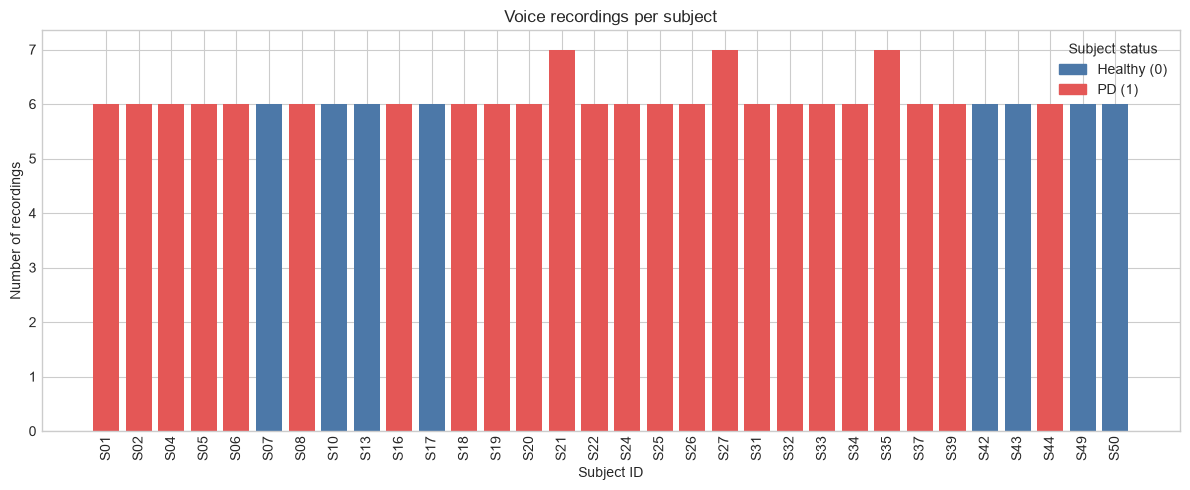

In [6]:
# Summarize recordings per speaker and verify status is available for coloring.
subject_summary = (
    oxford.groupby("subject_id", as_index=False)
    .agg(recordings=("name", "size"), status=("status", "first"))
    .sort_values("subject_id")
    .reset_index(drop=True)
)
display(subject_summary[["subject_id", "recordings", "status"]])

# Compute class balance from the loaded data, rather than typing results into the notebook.
recording_balance = oxford["status"].value_counts().sort_index().rename("recordings")
subject_balance = (
    subject_summary.groupby("status")["subject_id"].nunique().sort_index().rename("subjects")
)
class_balance = pd.concat([recording_balance, subject_balance], axis=1).fillna(0).astype(int)
class_balance.index = class_balance.index.map({0: "Healthy (0)", 1: "PD (1)"})
display(class_balance)

# An always-PD rule predicts the majority class at each unit of analysis.
recording_accuracy = float((oxford["status"] == 1).mean())
subject_accuracy = float((subject_summary["status"] == 1).mean())
print(f"Always-PD recording-level accuracy: {recording_accuracy:.3f}")
print(f"Always-PD subject-level accuracy: {subject_accuracy:.3f}")

# Color each speaker by their subject-level label to make the repeated-recording structure visible.
status_colors = subject_summary["status"].map({0: "#4C78A8", 1: "#E45756"})
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(subject_summary["subject_id"], subject_summary["recordings"], color=status_colors)
ax.set_title("Voice recordings per subject")
ax.set_xlabel("Subject ID")
ax.set_ylabel("Number of recordings")
ax.tick_params(axis="x", rotation=90)
legend_handles = [
    matplotlib.patches.Patch(color="#4C78A8", label="Healthy (0)"),
    matplotlib.patches.Patch(color="#E45756", label="PD (1)"),
]
ax.legend(handles=legend_handles, title="Subject status")
fig.tight_layout()

# Keep the notebook runnable when the optional report folder is absent or read-only.
save_fig(fig, "02_data_structure")
plt.show()

In [7]:
# State the baseline in values computed from the loaded recording and subject data.
healthy_subject_count = int((subject_summary["status"] == 0).sum())
print(
    f"Always-PD accuracy: recording level = {recording_accuracy:.3f}; "
    f"subject level = {subject_accuracy:.3f}."
)
print(f"Healthy subjects in this dataset: {healthy_subject_count}.")
print("Any model must clearly beat this baseline.")

Always-PD accuracy: recording level = 0.754; subject level = 0.750.
Healthy subjects in this dataset: 8.
Any model must clearly beat this baseline.


### Insight

The printed always-PD baseline gives a simple accuracy reference. Accuracy alone does not describe errors by class, and repeated recordings mean the subject—not an individual recording—is the unit for validation.

## 3. Exploratory analysis: subject-level patterns and feature structure

**Why this step:** Recordings from the same person are not independent. Statistical comparisons below use each person's mean across their recordings, so the comparison is at subject level rather than treating repeated measurements as new people. Treating repeated observations as independent is pseudoreplication: it can make the evidence look stronger than the number of independent people supports.

### 3.1 Subject-level comparison

**Why this step:** Comparing one mean per person avoids counting a speaker repeatedly. The AUC summarizes how often a randomly selected PD subject has a higher feature value than a randomly selected healthy subject; the two-sided Mann–Whitney test assesses rank differences. The recording-level p-value is included only to reveal the effect of ignoring repeated speakers.

Maximum vectorized vs Mann–Whitney AUC difference: 0


,Feature,Family,PD median (subject),Healthy median (subject),AUC (PD higher),AUC CI low,AUC CI high,Subject-level p,Naive recording p,Subject-level q,Effect size distance
0,spread1,nonlinear,-5.388812,-6.811117,0.927083,0.812500,1.000000,0.000088,1.592799e-16,0.001274,0.427083
1,PPE,nonlinear,0.226189,0.118826,0.921875,0.807292,1.000000,0.000116,1.592799e-16,0.001274,0.421875
2,MDVP:APQ,shimmer,0.022246,0.012719,0.875000,0.729167,0.979167,0.000940,1.269268e-11,0.006895,0.375000
3,spread2,nonlinear,0.244965,0.159968,0.859375,0.677083,0.994792,0.001683,7.159102e-11,0.009257,0.359375
4,MDVP:Shimmer(dB),shimmer,0.281833,0.146250,0.838542,0.677083,0.963542,0.003424,3.143455e-09,0.015066,0.338542
5,MDVP:Shimmer,shimmer,0.029966,0.016391,0.828125,0.661458,0.953125,0.004762,4.224740e-09,0.017461,0.328125
6,Shimmer:APQ5,shimmer,0.017181,0.009743,0.812500,0.645833,0.948047,0.007593,2.040180e-08,0.018560,0.312500
7,MDVP:RAP,jitter,0.002865,0.001575,0.812500,0.614583,0.979167,0.007593,8.689370e-09,0.018560,0.312500
8,Jitter:DDP,jitter,0.008591,0.004728,0.812500,0.614583,0.979167,0.007593,8.180063e-09,0.018560,0.312500
9,MDVP:PPQ,jitter,0.003099,0.001888,0.807292,0.624870,0.963542,0.008807,2.401494e-09,0.019375,0.307292


Figure saved to ../reports/figures/03_1_subject_auc.png


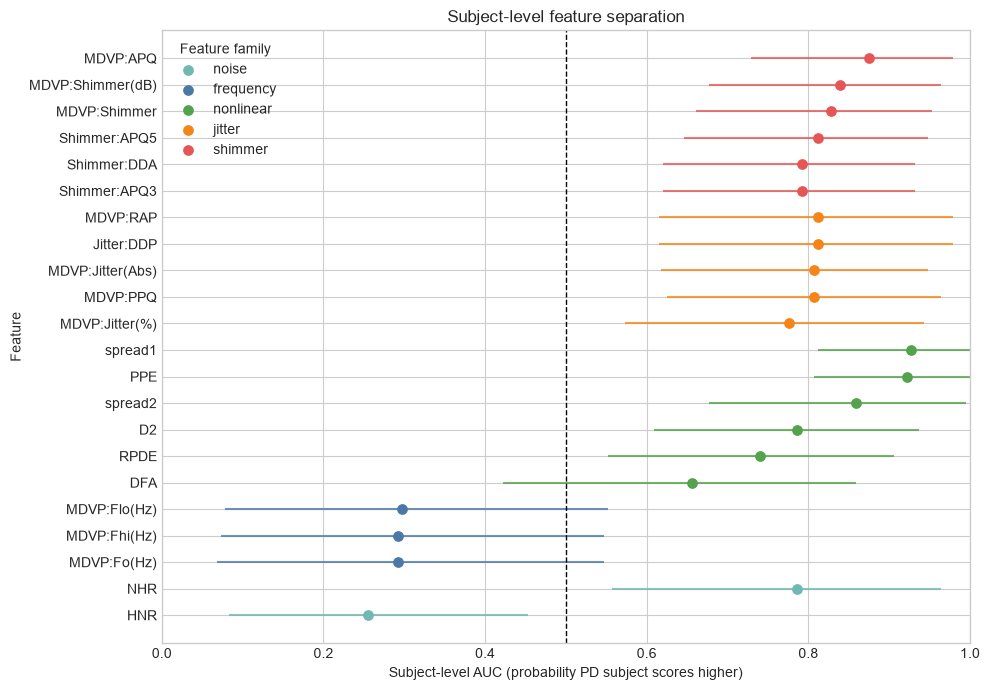

Figure saved to ../reports/figures/03_1_subject_strip.png


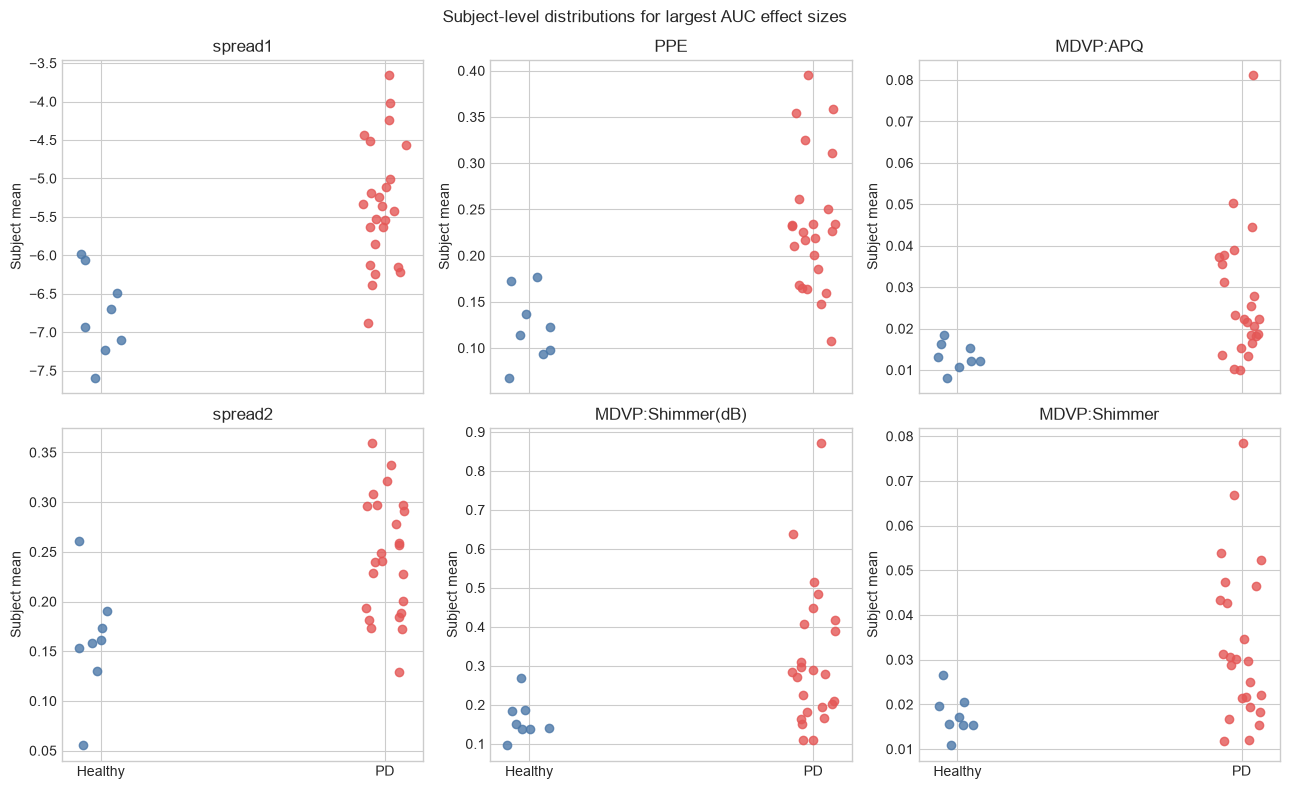

Features with subject-level q < 0.05: 16
Features with naive recording-level p < 0.05: 22
Top three features by absolute AUC distance: ['spread1', 'PPE', 'MDVP:APQ']
Features with a subject-bootstrap 95% CI excluding 0.5: 18


In [8]:
# Compare feature distributions using one average per subject and retain recording-level tests for contrast.
from scipy.stats import mannwhitneyu

feature_columns = [
    "MDVP:Fo(Hz)", "MDVP:Fhi(Hz)", "MDVP:Flo(Hz)",
    "MDVP:Jitter(%)", "MDVP:Jitter(Abs)", "MDVP:RAP", "MDVP:PPQ", "Jitter:DDP",
    "MDVP:Shimmer", "MDVP:Shimmer(dB)", "Shimmer:APQ3", "Shimmer:APQ5", "MDVP:APQ", "Shimmer:DDA",
    "NHR", "HNR", "RPDE", "DFA", "D2", "spread1", "spread2", "PPE",
]
feature_family = {
    feature: family
    for family, features in {
        "frequency": feature_columns[0:3],
        "jitter": feature_columns[3:8],
        "shimmer": feature_columns[8:14],
        "noise": feature_columns[14:16],
        "nonlinear": feature_columns[16:22],
    }.items()
    for feature in features
}
subject_means = (
    oxford.groupby("subject_id")[feature_columns].mean()
    .join(oxford.groupby("subject_id")["status"].first())
)
pd_subjects = subject_means[subject_means["status"] == 1]
healthy_subjects = subject_means[subject_means["status"] == 0]

# Bootstrap the two subject groups independently to preserve the sampling unit.
bootstrap_rng = np.random.RandomState(RANDOM_STATE)
bootstrap_resamples = 2000
pd_bootstrap_indices = bootstrap_rng.randint(
    0, len(pd_subjects), size=(bootstrap_resamples, len(pd_subjects))
)
healthy_bootstrap_indices = bootstrap_rng.randint(
    0, len(healthy_subjects), size=(bootstrap_resamples, len(healthy_subjects))
)
comparison_rows = []
auc_check_differences = []
for feature in feature_columns:
    # Mann–Whitney U is oriented as PD first, so U/(n_pd*n_healthy) estimates P(PD > healthy).
    pd_values = pd_subjects[feature].to_numpy(dtype=float)
    healthy_values = healthy_subjects[feature].to_numpy(dtype=float)
    subject_test = mannwhitneyu(pd_values, healthy_values, alternative="two-sided")
    auc = float(subject_test.statistic / (len(pd_values) * len(healthy_values)))
    direct_auc = float(np.mean(
        (pd_values[:, None] > healthy_values[None, :])
        + 0.5 * (pd_values[:, None] == healthy_values[None, :])
    ))
    auc_check_differences.append(abs(auc - direct_auc))

    # Vectorize all resampled pairwise comparisons for this feature.
    pd_bootstrap_values = pd_values[pd_bootstrap_indices][:, :, None]
    healthy_bootstrap_values = healthy_values[healthy_bootstrap_indices][:, None, :]
    bootstrap_auc = np.mean(
        (pd_bootstrap_values > healthy_bootstrap_values)
        + 0.5 * (pd_bootstrap_values == healthy_bootstrap_values),
        axis=(1, 2),
    )
    auc_ci_low, auc_ci_high = np.percentile(bootstrap_auc, [2.5, 97.5])
    naive_test = mannwhitneyu(
        oxford.loc[oxford["status"] == 1, feature],
        oxford.loc[oxford["status"] == 0, feature],
        alternative="two-sided",
    )
    comparison_rows.append(
        {
            "Feature": feature,
            "Family": feature_family[feature],
            "PD median (subject)": pd_subjects[feature].median(),
            "Healthy median (subject)": healthy_subjects[feature].median(),
            "AUC (PD higher)": auc,
            "AUC CI low": float(auc_ci_low),
            "AUC CI high": float(auc_ci_high),
            "Subject-level p": float(subject_test.pvalue),
            "Naive recording p": float(naive_test.pvalue),
        }
    )
comparison = pd.DataFrame(comparison_rows)
max_auc_difference = max(auc_check_differences)
if max_auc_difference > 1e-12:
    raise ValueError(
        "Vectorized AUC does not match the Mann–Whitney AUC; "
        f"maximum absolute difference was {max_auc_difference:.3g}."
    )
print(f"Maximum vectorized vs Mann–Whitney AUC difference: {max_auc_difference:.3g}")

# Apply Benjamini–Hochberg manually, then enforce monotonic adjusted p-values in reverse rank order.
raw_p = comparison["Subject-level p"].to_numpy()
order = np.argsort(raw_p)
ranked_q = raw_p[order] * len(raw_p) / np.arange(1, len(raw_p) + 1)
ranked_q = np.minimum.accumulate(ranked_q[::-1])[::-1]
q_values = np.empty_like(ranked_q)
q_values[order] = np.minimum(ranked_q, 1.0)
comparison["Subject-level q"] = q_values
comparison["Effect size distance"] = (comparison["AUC (PD higher)"] - 0.5).abs()
comparison = comparison.sort_values("Effect size distance", ascending=False).reset_index(drop=True)
display(comparison)

# Plot directional subject-level AUC values by their feature family.
family_colors = {
    "frequency": "#4C78A8", "jitter": "#F58518", "shimmer": "#E45756",
    "noise": "#72B7B2", "nonlinear": "#54A24B",
}
fig_auc, ax_auc = plt.subplots(figsize=(10, 7))
ordered = comparison.sort_values("AUC (PD higher)")
for family, group in ordered.groupby("Family", sort=False):
    ax_auc.hlines(
        y=group["Feature"], xmin=group["AUC CI low"], xmax=group["AUC CI high"],
        color=family_colors[family], linewidth=1.5, alpha=0.8,
    )
    ax_auc.scatter(group["AUC (PD higher)"], group["Feature"],
                   label=family, color=family_colors[family], s=45)
ax_auc.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax_auc.set_xlim(0, 1)
ax_auc.set_xlabel("Subject-level AUC (probability PD subject scores higher)")
ax_auc.set_ylabel("Feature")
ax_auc.set_title("Subject-level feature separation")
ax_auc.legend(title="Feature family", loc="best")
fig_auc.tight_layout()
save_fig(fig_auc, "03_1_subject_auc")
plt.show()

# Plot one point per subject for features with the largest absolute AUC distance from chance.
top_features = comparison.nlargest(6, "Effect size distance")["Feature"].tolist()
subject_jitter = np.random.RandomState(RANDOM_STATE)
fig_strip, axes_strip = plt.subplots(2, 3, figsize=(13, 8), sharex=True)
for ax, feature in zip(axes_strip.flat, top_features):
    for status, label, x_position, color in [(0, "Healthy", 0, "#4C78A8"), (1, "PD", 1, "#E45756")]:
        values = subject_means.loc[subject_means["status"] == status, feature].to_numpy()
        jitter = subject_jitter.uniform(-0.08, 0.08, size=len(values))
        ax.scatter(x_position + jitter, values, color=color, alpha=0.8, label=label)
    ax.set_title(feature)
    ax.set_xticks([0, 1], ["Healthy", "PD"])
    ax.set_ylabel("Subject mean")
fig_strip.suptitle("Subject-level distributions for largest AUC effect sizes")
fig_strip.tight_layout()
save_fig(fig_strip, "03_1_subject_strip")
plt.show()

# Print interpretation inputs directly from the computed table.
q_significant = int((comparison["Subject-level q"] < 0.05).sum())
naive_significant = int((comparison["Naive recording p"] < 0.05).sum())
top_three = comparison.nlargest(3, "Effect size distance")["Feature"].tolist()
print(f"Features with subject-level q < 0.05: {q_significant}")
print(f"Features with naive recording-level p < 0.05: {naive_significant}")
print(f"Top three features by absolute AUC distance: {top_three}")
ci_excludes_chance = int(
    ((comparison["AUC CI low"] > 0.5) | (comparison["AUC CI high"] < 0.5)).sum()
)
print(f"Features with a subject-bootstrap 95% CI excluding 0.5: {ci_excludes_chance}")

### Insight

Recording-level naive p-values can overstate evidence because repeated measurements from the same speaker are not independent. With only a small number of healthy subjects, statistical power is low; treat these comparisons as descriptive rather than conclusive.

The bootstrap intervals are wide because there are only 8 healthy subjects.

### 3.2 How much of each feature is who is speaking?

**Why this step:** This variance decomposition measures how much recording-to-recording spread is associated with differences between speakers. It helps explain why a random split can expose speaker-specific patterns to both training and test data.

,Feature,Family,Eta-squared
0,MDVP:Fo(Hz),frequency,0.944213
1,DFA,nonlinear,0.914408
2,HNR,noise,0.902882
3,RPDE,nonlinear,0.820159
4,MDVP:APQ,shimmer,0.819879
5,Shimmer:APQ5,shimmer,0.817317
6,MDVP:PPQ,jitter,0.805673
7,MDVP:Shimmer(dB),shimmer,0.798022
8,MDVP:Shimmer,shimmer,0.792867
9,PPE,nonlinear,0.788670


Figure saved to ../reports/figures/03_2_subject_variation.png


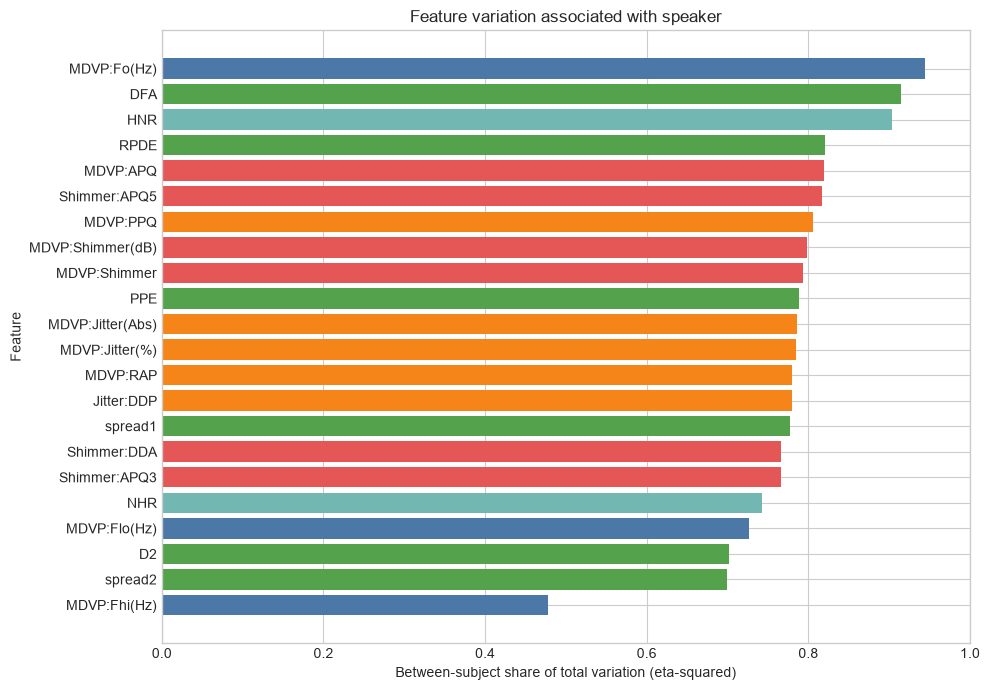

Median eta-squared across features: 0.786
Features with eta-squared above 0.8: ['MDVP:Fo(Hz)', 'DFA', 'HNR', 'RPDE', 'MDVP:APQ', 'Shimmer:APQ5', 'MDVP:PPQ']
Eta-squared expected by chance if speaker has no effect: 0.1598


In [9]:
# Decompose each feature's total sum of squares into between-speaker variation.
eta_rows = []
for feature in feature_columns:
    values = oxford[feature].to_numpy(dtype=float)
    grand_mean = float(values.mean())
    grouped = oxford.groupby("subject_id")[feature].agg(["mean", "size"])
    ss_between = float((grouped["size"] * (grouped["mean"] - grand_mean) ** 2).sum())
    ss_total = float(((values - grand_mean) ** 2).sum())
    eta_squared = ss_between / ss_total if ss_total > 0 else float("nan")
    eta_rows.append({"Feature": feature, "Family": feature_family[feature], "Eta-squared": eta_squared})
eta_table = pd.DataFrame(eta_rows).sort_values("Eta-squared", ascending=False).reset_index(drop=True)
display(eta_table)

# Show the decomposition values in a family-colored chart.
fig_eta, ax_eta = plt.subplots(figsize=(10, 7))
bar_colors = [family_colors[family] for family in eta_table["Family"]]
ax_eta.barh(eta_table["Feature"], eta_table["Eta-squared"], color=bar_colors)
ax_eta.invert_yaxis()
ax_eta.set_xlim(0, 1)
ax_eta.set_xlabel("Between-subject share of total variation (eta-squared)")
ax_eta.set_ylabel("Feature")
ax_eta.set_title("Feature variation associated with speaker")
fig_eta.tight_layout()
save_fig(fig_eta, "03_2_subject_variation")
plt.show()

# Print summary values computed from the eta-squared table.
median_eta_squared = float(eta_table["Eta-squared"].median())
features_above_08 = eta_table.loc[eta_table["Eta-squared"] > 0.8, "Feature"].tolist()
n_subjects = int(oxford["subject_id"].nunique())
n_recordings = int(len(oxford))
eta_squared_chance = (n_subjects - 1) / (n_recordings - 1)
print(f"Median eta-squared across features: {median_eta_squared:.3f}")
print(f"Features with eta-squared above 0.8: {features_above_08}")
print(f"Eta-squared expected by chance if speaker has no effect: {eta_squared_chance:.4f}")

### Insight

High eta-squared values mean much of the variation between recordings is variation between people. This is exactly why a random split can let a model memorize speakers, setting up the leakage checks in later sections; no model performance is inferred here.

Eta-squared is biased upward with few recordings per speaker, so compare it with the printed chance reference rather than with zero. Because status is constant within each person, between-person variation also contains any disease signal; eta-squared alone does not prove speakers are identifiable. Section 4 tests that directly.

### 3.3 Redundancy

**Why this step:** Highly correlated measurements can encode overlapping information. Mapping redundancy helps avoid overinterpreting coefficients or single-feature importance.

Figure saved to ../reports/figures/03_3_spearman_clusters.png


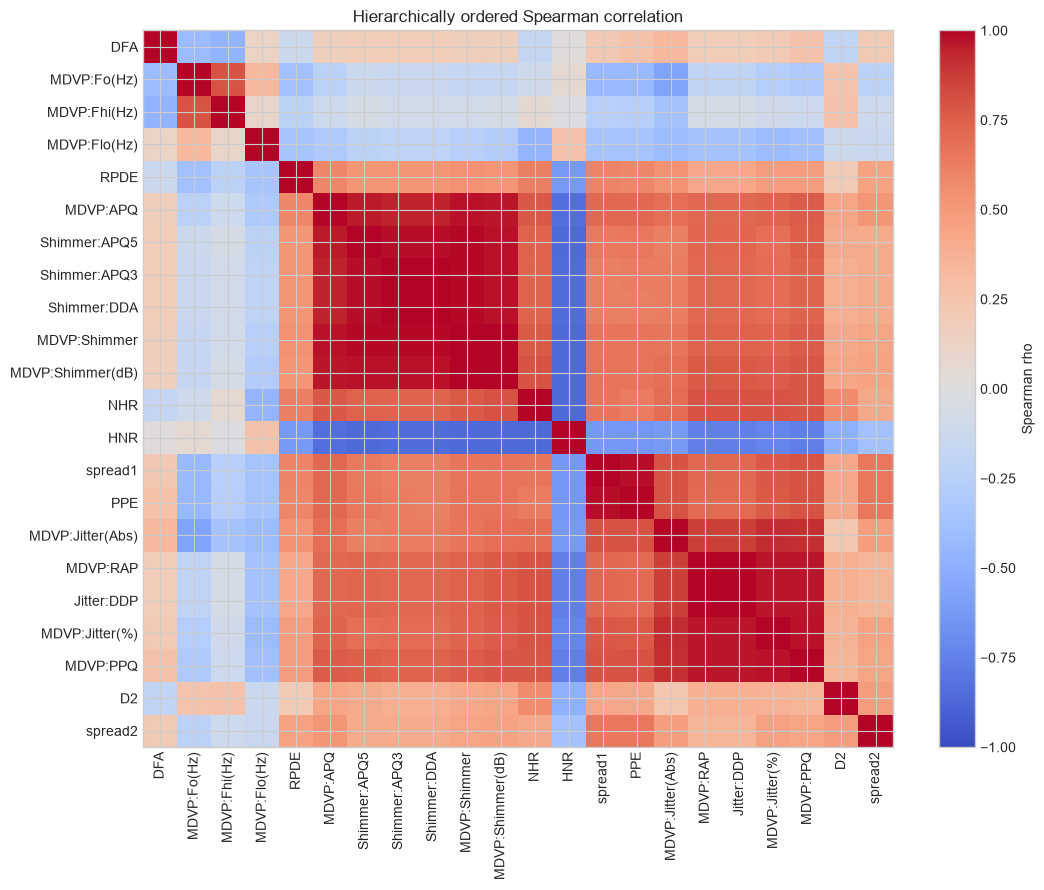

,Feature 1,Feature 2,Spearman rho
0,MDVP:Jitter(%),MDVP:RAP,0.961959
1,MDVP:Jitter(%),MDVP:PPQ,0.970870
2,MDVP:Jitter(%),Jitter:DDP,0.962034
3,MDVP:RAP,MDVP:PPQ,0.966433
4,MDVP:RAP,Jitter:DDP,0.999980
5,MDVP:PPQ,Jitter:DDP,0.966411
6,MDVP:Shimmer,MDVP:Shimmer(dB),0.993185
7,MDVP:Shimmer,Shimmer:APQ3,0.988902
8,MDVP:Shimmer,Shimmer:APQ5,0.987025
9,MDVP:Shimmer,MDVP:APQ,0.972329


Jitter:DDP vs 3 x MDVP:RAP: maximum absolute relative difference 0.00438596; Spearman correlation 0.999980; consistent with an exact 3x relationship.
Shimmer:DDA vs 3 x Shimmer:APQ3: maximum absolute relative difference 0.000732601; Spearman correlation 0.999998; consistent with an exact 3x relationship.


In [10]:
# Cluster features by absolute Spearman association, so inverse relationships are also grouped.
spearman_matrix = oxford[feature_columns].corr(method="spearman")
correlation_distance = 1.0 - np.abs(spearman_matrix.to_numpy())
np.fill_diagonal(correlation_distance, 0.0)
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

condensed_distance = squareform(correlation_distance, checks=False)
cluster_tree = linkage(condensed_distance, method="average")
cluster_order = leaves_list(cluster_tree)
ordered_features = [feature_columns[index] for index in cluster_order]
ordered_corr = spearman_matrix.loc[ordered_features, ordered_features]
fig_corr, ax_corr = plt.subplots(figsize=(11, 9))
image = ax_corr.imshow(ordered_corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax_corr.set_xticks(range(len(ordered_features)), ordered_features, rotation=90)
ax_corr.set_yticks(range(len(ordered_features)), ordered_features)
ax_corr.set_title("Hierarchically ordered Spearman correlation")
fig_corr.colorbar(image, ax=ax_corr, label="Spearman rho")
fig_corr.tight_layout()
save_fig(fig_corr, "03_3_spearman_clusters")
plt.show()

# List each unique feature pair whose absolute rank correlation meets the threshold.
pair_rows = []
for left_index, left_feature in enumerate(feature_columns):
    for right_feature in feature_columns[left_index + 1:]:
        rho = float(spearman_matrix.loc[left_feature, right_feature])
        if abs(rho) >= 0.95:
            pair_rows.append({"Feature 1": left_feature, "Feature 2": right_feature, "Spearman rho": rho})
high_correlation_pairs = pd.DataFrame(pair_rows, columns=["Feature 1", "Feature 2", "Spearman rho"])
display(high_correlation_pairs)

# Check the expected algebraic relationships and report both relative error and rank correlation.
def check_three_x_relationship(target_column, base_column):
    expected_values = 3.0 * oxford[base_column].to_numpy(dtype=float)
    observed_values = oxford[target_column].to_numpy(dtype=float)
    denominator = np.abs(expected_values)
    relative_difference = np.divide(
        np.abs(observed_values - expected_values), denominator,
        out=np.zeros_like(denominator), where=denominator > 0,
    )
    max_relative_difference = float(relative_difference.max())
    rho = float(spearman_matrix.loc[target_column, base_column])
    conclusion = (
        "consistent with an exact 3x relationship"
        if max_relative_difference < 0.01
        else "not an exact 3x multiple"
    )
    print(
        f"{target_column} vs 3 x {base_column}: maximum absolute relative difference "
        f"{max_relative_difference:.6g}; Spearman correlation {rho:.6f}; {conclusion}."
    )

check_three_x_relationship("Jitter:DDP", "MDVP:RAP")
check_three_x_relationship("Shimmer:DDA", "Shimmer:APQ3")

### Insight

Collinearity can make linear-model coefficients unstable or difficult to interpret. Permutation importance can also be shared among correlated features, so later interpretation should consider groups of related features by family.

### 3.4 Shape

**Why this step:** Feature skewness describes asymmetry in the observed distributions and can guide a later, pipeline-contained test of skew handling.

,Feature,Family,Skewness,Absolute skewness
0,NHR,noise,4.220709,4.220709
1,Jitter:DDP,jitter,3.362058,3.362058
2,MDVP:RAP,jitter,3.360708,3.360708
3,MDVP:Jitter(%),jitter,3.084946,3.084946
4,MDVP:PPQ,jitter,3.073892,3.073892
5,MDVP:Jitter(Abs),jitter,2.649071,2.649071
6,MDVP:APQ,shimmer,2.618047,2.618047
7,MDVP:Fhi(Hz),frequency,2.542146,2.542146
8,MDVP:Shimmer(dB),shimmer,1.999389,1.999389
9,Shimmer:APQ5,shimmer,1.798697,1.798697


Figure saved to ../reports/figures/03_4_feature_skewness.png


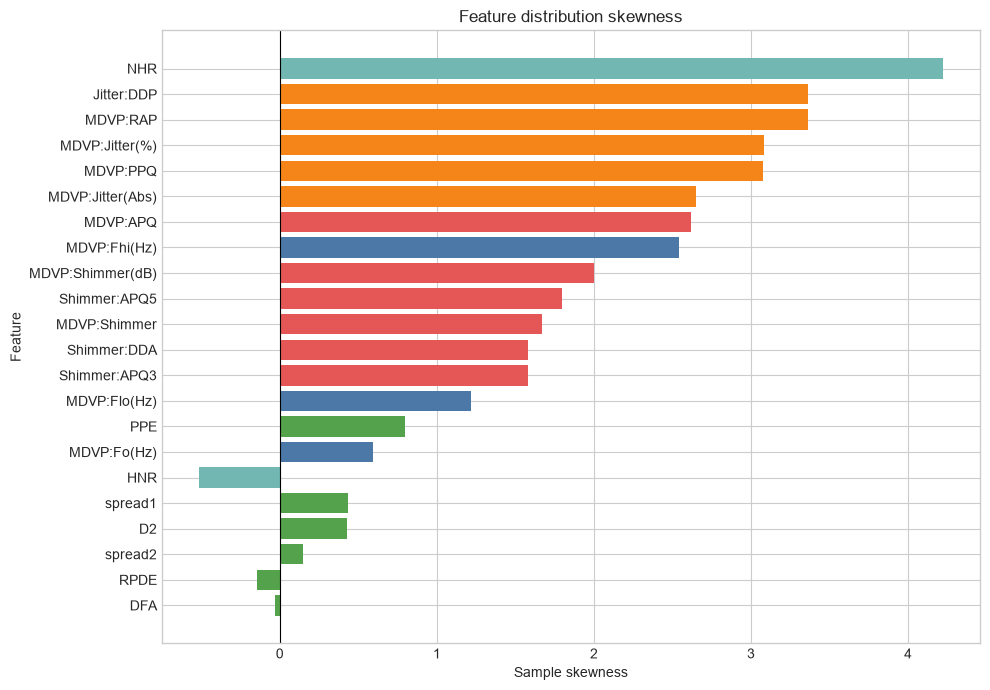

Features with absolute skewness above 1: 14


In [11]:
# Calculate sample skewness for each voice feature and order by absolute magnitude.
skew_rows = []
for feature in feature_columns:
    skew_rows.append({"Feature": feature, "Family": feature_family[feature], "Skewness": float(oxford[feature].skew())})
skew_table = pd.DataFrame(skew_rows)
skew_table["Absolute skewness"] = skew_table["Skewness"].abs()
skew_table = skew_table.sort_values("Absolute skewness", ascending=False).reset_index(drop=True)
display(skew_table)

# Plot signed skewness with colors keyed to the same feature families.
fig_skew, ax_skew = plt.subplots(figsize=(10, 7))
skew_colors = [family_colors[family] for family in skew_table["Family"]]
ax_skew.barh(skew_table["Feature"], skew_table["Skewness"], color=skew_colors)
ax_skew.invert_yaxis()
ax_skew.axvline(0, color="black", linewidth=0.8)
ax_skew.set_xlabel("Sample skewness")
ax_skew.set_ylabel("Feature")
ax_skew.set_title("Feature distribution skewness")
fig_skew.tight_layout()
save_fig(fig_skew, "03_4_feature_skewness")
plt.show()

# Count features beyond the stated descriptive skew threshold.
strongly_skewed_count = int((skew_table["Absolute skewness"] > 1).sum())
print(f"Features with absolute skewness above 1: {strongly_skewed_count}")

### Insight

Scaling will live inside model pipelines, and a power transform will be tested as a pipeline option later. No feature is transformed in this exploratory step.

### 3.5 Picture of the structure

**Why this step:** A two-dimensional projection is a compact visual summary of variation in the measured features. This PCA is descriptive only, is fit on all observations for visualization, and is never used for evaluation.

Figure saved to ../reports/figures/03_5_pca_descriptive.png


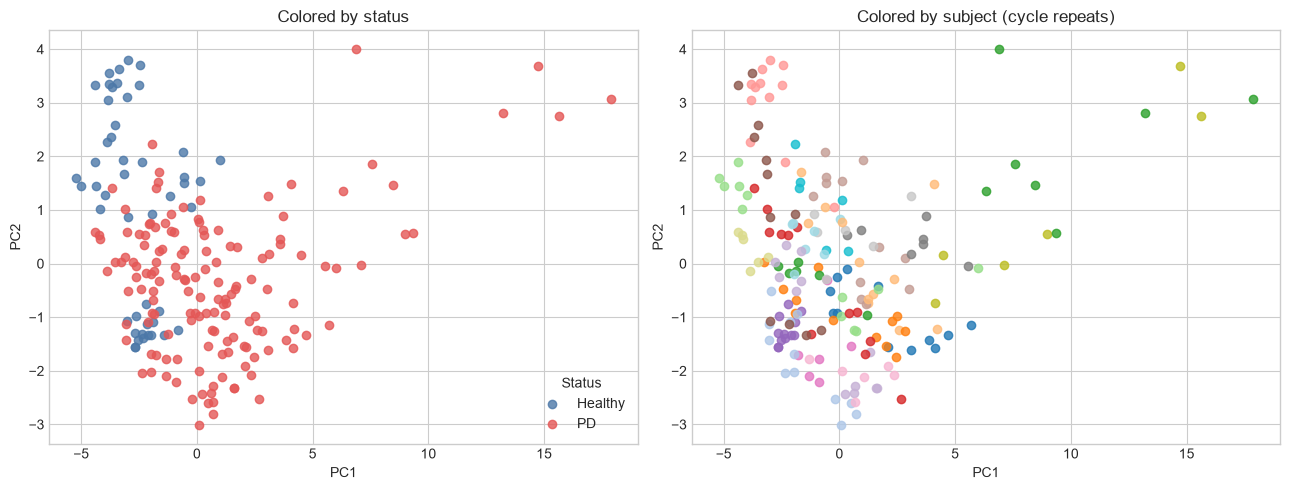

PCA PC1 explained variance ratio: 0.5890
PCA PC2 explained variance ratio: 0.1130


In [12]:
# Standardize features before PCA because voice measurements use different scales.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

standardized_features = StandardScaler().fit_transform(oxford[feature_columns])
pca_model = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coordinates = pca_model.fit_transform(standardized_features)
pca_frame = pd.DataFrame(
    {"PC1": pca_coordinates[:, 0], "PC2": pca_coordinates[:, 1],
     "status": oxford["status"].to_numpy(), "subject_id": oxford["subject_id"].to_numpy()}
)

# Use separate panels for disease status and speaker identity; subject colors repeat deliberately.
fig_pca, (ax_status, ax_subject) = plt.subplots(1, 2, figsize=(13, 5))
for status, label, color in [(0, "Healthy", "#4C78A8"), (1, "PD", "#E45756")]:
    rows = pca_frame[pca_frame["status"] == status]
    ax_status.scatter(rows["PC1"], rows["PC2"], label=label, color=color, alpha=0.8)
ax_status.set_title("Colored by status")
ax_status.set_xlabel("PC1")
ax_status.set_ylabel("PC2")
ax_status.legend(title="Status")
subject_ids = sorted(pca_frame["subject_id"].unique())
subject_palette = plt.cm.tab20(np.linspace(0, 1, 20))
for subject_index, subject_id in enumerate(subject_ids):
    rows = pca_frame[pca_frame["subject_id"] == subject_id]
    ax_subject.scatter(rows["PC1"], rows["PC2"], color=subject_palette[subject_index % len(subject_palette)], alpha=0.8)
ax_subject.set_title("Colored by subject (cycle repeats)")
ax_subject.set_xlabel("PC1")
ax_subject.set_ylabel("PC2")
fig_pca.tight_layout()
save_fig(fig_pca, "03_5_pca_descriptive")
plt.show()

# Print the variance ratios calculated from the descriptive PCA fit.
print(f"PCA PC1 explained variance ratio: {pca_model.explained_variance_ratio_[0]:.4f}")
print(f"PCA PC2 explained variance ratio: {pca_model.explained_variance_ratio_[1]:.4f}")

### Insight

This projection is a descriptive picture only. Because PCA was fit on all recordings, it must not be used to estimate evaluation performance or guide a held-out test result.

### 3.6 What the EDA means for modelling

**Why this step:** The exploratory checks inform safeguards and candidate preprocessing choices, but they do not replace validation.

Validation must be subject-grouped to keep speakers separate. Scaling belongs inside pipelines to prevent leakage across folds. Correlated measurements call for collinearity-aware interpretation by feature family. Skew handling should be tested as an option rather than assumed to help. The small number of independent subjects calls for caution when interpreting any later results.

## 4. Can a model tell WHO is speaking?

**Why this step:** In this dataset the PD label belongs to the person, not the recording. If voice features reveal who is speaking, a model can score well by recognizing the speaker instead of detecting disease. This section tests whether speakers are identifiable and demonstrates the shortcut. No genuine PD model is trained here.

### 4.1 Speaker identification

**Why this step:** Predicting speaker identity directly checks whether voice measurements contain a recognizable personal signature. The repeated stratified folds ensure the speaker classes are represented consistently while recordings from the same speaker can still appear in both training and test data for this deliberate leakage demonstration.

In [13]:
# Set up repeated, stratified recording-level folds for the identity-leakage demonstration.
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

minimum_recordings = int(oxford.groupby("subject_id").size().min())
if minimum_recordings < 5:
    raise ValueError(
        "Repeated 5-fold speaker stratification requires at least 5 recordings "
        f"per subject; found minimum {minimum_recordings}."
    )
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
X_identity = oxford[feature_columns]
y_identity = oxford["subject_id"].to_numpy()

# Scaling must be fitted separately inside each training fold.
def make_identity_pipeline(estimator):
    return Pipeline([("scale", StandardScaler()), ("model", estimator)])

identity_estimators = {
    "Logistic regression": LogisticRegression(max_iter=10000),
    "1-nearest neighbor": KNeighborsClassifier(n_neighbors=1),
    "Random forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=1
    ),
}
identity_rows = []
identity_scores = {}
for model_name, estimator in identity_estimators.items():
    scores = cross_val_score(
        make_identity_pipeline(estimator), X_identity, y_identity,
        cv=cv, scoring="accuracy", n_jobs=1,
    )
    identity_scores[model_name] = scores
    identity_rows.append({
        "Model": model_name,
        "Mean accuracy": float(scores.mean()),
        "Std over folds": float(scores.std()),
        "Minimum": float(scores.min()),
        "Maximum": float(scores.max()),
    })
identity_results = pd.DataFrame(identity_rows)
display(identity_results)

# Compute chance and largest-class reference levels from the actual recording labels.
number_of_subjects = int(pd.Series(y_identity).nunique())
chance_accuracy = 1.0 / number_of_subjects
largest_subject_share = float(pd.Series(y_identity).value_counts().max() / len(y_identity))
print(f"Chance identity accuracy (1 / number of subjects): {chance_accuracy:.4f}")
print(f"Largest-subject recording share: {largest_subject_share:.4f}")

# Permuting identity labels is a negative control: features should not predict shuffled identities.
permuted_identity = np.random.RandomState(RANDOM_STATE).permutation(y_identity)
permuted_scores = cross_val_score(
    make_identity_pipeline(LogisticRegression(max_iter=10000)),
    X_identity, permuted_identity, cv=cv, scoring="accuracy", n_jobs=1,
)
print(f"Permuted-identity logistic-regression mean accuracy: {permuted_scores.mean():.4f}")

,Model,Mean accuracy,Std over folds,Minimum,Maximum
0,Logistic regression,0.807179,0.053844,0.692308,0.897436
1,1-nearest neighbor,0.791795,0.059061,0.666667,0.871795
2,Random forest,0.829744,0.049656,0.743590,0.897436


Chance identity accuracy (1 / number of subjects): 0.0312
Largest-subject recording share: 0.0359


Permuted-identity logistic-regression mean accuracy: 0.0215


### Insight

The chance and largest-subject reference values and each model's fold summary are printed above. The permuted-label result is a negative control: it shows how the same pipeline behaves when the identity labels no longer correspond to the original speakers.

### 4.2 Which feature families carry identity?

**Why this step:** Comparing feature families shows whether speaker identity is present throughout the voice measurements or concentrated in a subset. Each model remains inside a pipeline so scaling uses training-fold data only.

,Feature family,Mean accuracy
0,all features,0.807179
1,nonlinear,0.594872
2,jitter,0.290256
3,shimmer,0.277949
4,frequency,0.243077
5,noise,0.182564


Figure saved to ../reports/figures/04_2_identity_by_family.png


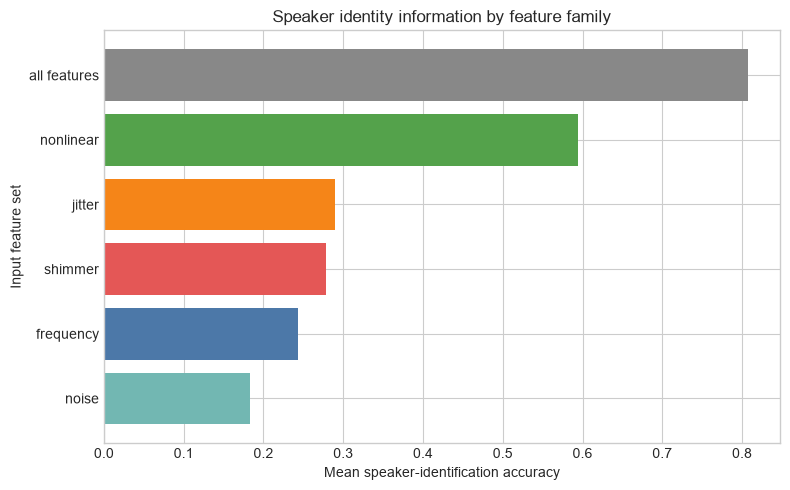

Identity accuracy ranking, highest to lowest: ['all features', 'nonlinear', 'jitter', 'shimmer', 'frequency', 'noise']


In [14]:
# Evaluate identity accuracy using each acoustic family and all measured features.
family_feature_columns = {
    family: [feature for feature in feature_columns if feature_family[feature] == family]
    for family in ["frequency", "jitter", "shimmer", "noise", "nonlinear"]
}
family_feature_columns["all features"] = feature_columns
family_identity_rows = []
for family, columns in family_feature_columns.items():
    scores = cross_val_score(
        make_identity_pipeline(LogisticRegression(max_iter=10000)),
        oxford[columns], y_identity, cv=cv, scoring="accuracy", n_jobs=1,
    )
    family_identity_rows.append({"Feature family": family, "Mean accuracy": float(scores.mean())})
family_identity = pd.DataFrame(family_identity_rows).sort_values(
    "Mean accuracy", ascending=True
).reset_index(drop=True)
display(family_identity.sort_values("Mean accuracy", ascending=False).reset_index(drop=True))

# Compare family-only identity accuracy with the all-feature reference.
family_bar_colors = [
    "#888888" if family == "all features" else family_colors[family]
    for family in family_identity["Feature family"]
]
fig_family, ax_family = plt.subplots(figsize=(8, 5))
ax_family.barh(family_identity["Feature family"], family_identity["Mean accuracy"], color=family_bar_colors)
ax_family.set_xlabel("Mean speaker-identification accuracy")
ax_family.set_ylabel("Input feature set")
ax_family.set_title("Speaker identity information by feature family")
fig_family.tight_layout()
save_fig(fig_family, "04_2_identity_by_family")
plt.show()
family_ranking = family_identity.sort_values("Mean accuracy", ascending=False)["Feature family"].tolist()
print(f"Identity accuracy ranking, highest to lowest: {family_ranking}")

### Insight

Feature families that also separate PD from healthy subjects can identify speakers too. That overlap reinforces why speaker-aware validation is essential before interpreting disease predictions.

### 4.3 Which speakers are identifiable?

**Why this step:** A per-subject out-of-fold share shows whether identity accuracy is uniform or driven by a subset of speakers. Each recording receives a prediction from a fold where it was held out.

,subject_id,status,correct_share
0,S42,0,0.333333
1,S04,1,0.500000
2,S34,1,0.500000
3,S19,1,0.500000
4,S39,1,0.500000
5,S26,1,0.666667
6,S06,1,0.666667
7,S44,1,0.666667
8,S37,1,0.666667
9,S25,1,0.833333


Figure saved to ../reports/figures/04_3_identity_by_subject.png


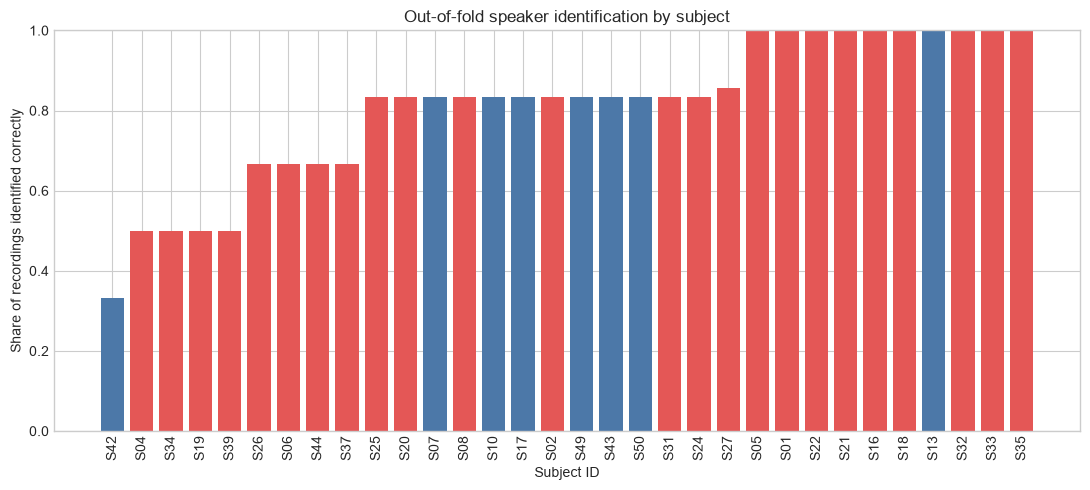

Mean per-subject share identified correctly: 0.8080
Five lowest subjects and correct shares: [('S42', 0.3333), ('S04', 0.5), ('S34', 0.5), ('S19', 0.5), ('S39', 0.5)]


In [15]:
# Generate one held-out identity prediction for each recording using stratified folds.
identity_oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
identity_oof_predictions = cross_val_predict(
    make_identity_pipeline(LogisticRegression(max_iter=10000)),
    X_identity, y_identity, cv=identity_oof_cv, method="predict", n_jobs=1,
)
oof_identity = oxford[["subject_id", "status"]].copy()
oof_identity["predicted_subject"] = identity_oof_predictions
oof_identity["correct"] = oof_identity["subject_id"].to_numpy() == identity_oof_predictions
subject_identifiability = (
    oof_identity.groupby(["subject_id", "status"], as_index=False)
    .agg(correct_share=("correct", "mean"))
    .sort_values("correct_share")
    .reset_index(drop=True)
)
display(subject_identifiability)

# Color speakers by the recorded disease label, matching Section 2's palette.
subject_colors = subject_identifiability["status"].map({0: "#4C78A8", 1: "#E45756"})
fig_subject_id, ax_subject_id = plt.subplots(figsize=(11, 5))
ax_subject_id.bar(
    subject_identifiability["subject_id"],
    subject_identifiability["correct_share"],
    color=subject_colors,
)
ax_subject_id.set_ylim(0, 1)
ax_subject_id.set_xlabel("Subject ID")
ax_subject_id.set_ylabel("Share of recordings identified correctly")
ax_subject_id.set_title("Out-of-fold speaker identification by subject")
ax_subject_id.tick_params(axis="x", rotation=90)
fig_subject_id.tight_layout()
save_fig(fig_subject_id, "04_3_identity_by_subject")
plt.show()

mean_identifiability = float(subject_identifiability["correct_share"].mean())
lowest_five_subjects = list(zip(
    subject_identifiability["subject_id"].head(5),
    subject_identifiability["correct_share"].head(5).round(4),
))
print(f"Mean per-subject share identified correctly: {mean_identifiability:.4f}")
print(f"Five lowest subjects and correct shares: {lowest_five_subjects}")

### Insight

The per-subject out-of-fold shares show how identity recognition varies across people. These are speaker-identification results, not disease-detection results.

### 4.4 The speaker-lookup shortcut for PD

**Why this step:** This deliberately uses a speaker prediction followed by that speaker's status in the training rows. It demonstrates how disease labels can appear predictable when the same people are present on both sides of a random recording split, without fitting a disease classifier.

In [16]:
# Use the exact repeated folds from the identity experiment, then map predicted speakers to training status.
shortcut_fold_rows = []
pooled_true_status = []
pooled_shortcut_status = []
pooled_baseline_status = []
true_status_all = oxford["status"].to_numpy()
for fold_index, (train_indices, test_indices) in enumerate(cv.split(X_identity, y_identity), start=1):
    identity_model = make_identity_pipeline(LogisticRegression(max_iter=10000))
    identity_model.fit(X_identity.iloc[train_indices], y_identity[train_indices])
    predicted_speakers = identity_model.predict(X_identity.iloc[test_indices])

    # Each speaker appears in training because this split is stratified over recording-level speakers.
    train_status_lookup = (
        oxford.iloc[train_indices].groupby("subject_id")["status"].first().to_dict()
    )
    if any(speaker not in train_status_lookup for speaker in predicted_speakers):
        raise ValueError("A predicted speaker was absent from the training status lookup.")
    shortcut_predictions = np.asarray(
        [train_status_lookup[speaker] for speaker in predicted_speakers], dtype=int
    )
    y_true_fold = true_status_all[test_indices]
    baseline_predictions = np.ones(len(test_indices), dtype=int)

    def fold_metrics(y_true, y_pred):
        # Return accuracy, PD recall, and healthy specificity with zero-division guards.
        positive_count = int((y_true == 1).sum())
        healthy_count = int((y_true == 0).sum())
        recall = float(((y_true == 1) & (y_pred == 1)).sum() / positive_count) if positive_count else 0.0
        specificity = float(((y_true == 0) & (y_pred == 0)).sum() / healthy_count) if healthy_count else 0.0
        return float(accuracy_score(y_true, y_pred)), recall, specificity

    shortcut_metrics = fold_metrics(y_true_fold, shortcut_predictions)
    baseline_metrics = fold_metrics(y_true_fold, baseline_predictions)
    shortcut_fold_rows.append({
        "Fold": fold_index,
        "Shortcut accuracy": shortcut_metrics[0],
        "Shortcut PD recall": shortcut_metrics[1],
        "Shortcut healthy specificity": shortcut_metrics[2],
        "Always-PD accuracy": baseline_metrics[0],
        "Always-PD PD recall": baseline_metrics[1],
        "Always-PD healthy specificity": baseline_metrics[2],
    })
    pooled_true_status.extend(y_true_fold.tolist())
    pooled_shortcut_status.extend(shortcut_predictions.tolist())
    pooled_baseline_status.extend(baseline_predictions.tolist())

shortcut_folds = pd.DataFrame(shortcut_fold_rows)
shortcut_summary_rows = []
for metric in ["accuracy", "PD recall", "healthy specificity"]:
    shortcut_values = shortcut_folds[f"Shortcut {metric}"]
    baseline_values = shortcut_folds[f"Always-PD {metric}"]
    shortcut_summary_rows.append({
        "Metric": metric,
        "Lookup mean": float(shortcut_values.mean()),
        "Lookup std": float(shortcut_values.std()),
        "Always-PD mean": float(baseline_values.mean()),
        "Always-PD std": float(baseline_values.std()),
    })
shortcut_summary = pd.DataFrame(shortcut_summary_rows)
display(shortcut_summary)

# Aggregate all held-out predictions into a pooled confusion matrix for the lookup shortcut.
pooled_matrix = confusion_matrix(pooled_true_status, pooled_shortcut_status, labels=[0, 1])
pooled_confusion = pd.DataFrame(
    pooled_matrix,
    index=["Actual healthy", "Actual PD"],
    columns=["Predicted healthy", "Predicted PD"],
)
display(pooled_confusion)

lookup_accuracy_mean = float(shortcut_folds["Shortcut accuracy"].mean())
lookup_recall_mean = float(shortcut_folds["Shortcut PD recall"].mean())
lookup_specificity_mean = float(shortcut_folds["Shortcut healthy specificity"].mean())
baseline_accuracy_mean = float(shortcut_folds["Always-PD accuracy"].mean())
baseline_recall_mean = float(shortcut_folds["Always-PD PD recall"].mean())
baseline_specificity_mean = float(shortcut_folds["Always-PD healthy specificity"].mean())
print(
    f"Speaker-lookup mean accuracy={lookup_accuracy_mean:.4f}, "
    f"PD recall={lookup_recall_mean:.4f}, healthy specificity={lookup_specificity_mean:.4f}."
)
print(
    f"Always-PD baseline mean accuracy={baseline_accuracy_mean:.4f}, "
    f"PD recall={baseline_recall_mean:.4f}, healthy specificity={baseline_specificity_mean:.4f}."
)
print(f"Pooled speaker-lookup confusion matrix: {pooled_matrix.tolist()}")

,Metric,Lookup mean,Lookup std,Always-PD mean,Always-PD std
0,accuracy,0.925128,0.038405,0.753846,0.020936
1,PD recall,0.938355,0.038636,1.000000,0.000000
2,healthy specificity,0.882343,0.108876,0.000000,0.000000


,Predicted healthy,Predicted PD
Actual healthy,212,28
Actual PD,45,690


Speaker-lookup mean accuracy=0.9251, PD recall=0.9384, healthy specificity=0.8823.
Always-PD baseline mean accuracy=0.7538, PD recall=1.0000, healthy specificity=0.0000.
Pooled speaker-lookup confusion matrix: [[212, 28], [45, 690]]


### Insight

This is **not a diagnostic model**. The shortcut only works because the same people appear in training and test: it predicts a speaker, then retrieves that speaker's status from training rows. Under subject-grouped splitting it cannot work because test speakers are never seen in training, by construction.

### 4.5 What this leakage demonstration means

All Parkinson's models in this notebook must be validated with subject-grouped splits. A random split is used only to demonstrate inflation. Section 5 quantifies it with real Parkinson's classifiers.